# Análisis Exploratorio de Datos (EDA) — Proyecto GasIA
**Universidad Industrial de Santander — Sede Barrancabermeja**  
**Semillero de Inteligencia Artificial Aplicada a Sistemas de Ingeniería**

**Integrantes:**
* Sebastian David Tang Gutierrez (2264049)
* Danna Valentina Perez Alvarado (2254262)
* Edison Bayardo Puerto Maldonado (2254239)
* Pathy Alexandra Rache Guaman (2254260)
* Arianalucia Cogollos Fernandez (2254202)

### Pregunta de Investigación para el EDA
¿Cómo se comportan las lecturas de concentración de gases frente a las variaciones de temperatura y humedad ambiental, y qué diferencias estadísticas permiten distinguir una condición segura de una alerta temprana?

**Unidad de observación:** Cada fila del conjunto de datos representa una lectura temporal capturada por un arreglo de sensores IoT en un instante dado (tasa de muestreo de 1 Hz).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")

# Cargar el dataset descartando la columna de índice sin nombre (Unnamed: 0)
df = pd.read_csv("datos/smoke_detection_iot.csv", index_col=0)

print(f"Dimensiones del dataset: {df.shape[0]} observaciones y {df.shape[1]} variables.")
display(df.head(5))
df.info()
display(df.describe())

Dimensiones del dataset: 62630 observaciones y 15 variables.


,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


<class 'pandas.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UTC             62630 non-null  int64  
 1   Temperature[C]  62630 non-null  float64
 2   Humidity[%]     62630 non-null  float64
 3   TVOC[ppb]       62630 non-null  int64  
 4   eCO2[ppm]       62630 non-null  int64  
 5   Raw H2          62630 non-null  int64  
 6   Raw Ethanol     62630 non-null  int64  
 7   Pressure[hPa]   62630 non-null  float64
 8   PM1.0           62630 non-null  float64
 9   PM2.5           62630 non-null  float64
 10  NC0.5           62630 non-null  float64
 11  NC1.0           62630 non-null  float64
 12  NC2.5           62630 non-null  float64
 13  CNT             62630 non-null  int64  
 14  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(7)
memory usage: 7.2 MB


,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
count,6.263000e+04,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000
mean,1.654792e+09,15.970424,48.539499,1942.057528,670.021044,12942.453936,19754.257912,938.627649,100.594309,184.467770,491.463608,203.586487,80.049042,10511.386157,0.714626
std,1.100025e+05,14.359576,8.865367,7811.589055,1905.885439,272.464305,609.513156,1.331344,922.524245,1976.305615,4265.661251,2214.738556,1083.383189,7597.870997,0.451596
min,1.654712e+09,-22.010000,10.740000,0.000000,400.000000,10668.000000,15317.000000,930.852000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.654743e+09,10.994250,47.530000,130.000000,400.000000,12830.000000,19435.000000,938.700000,1.280000,1.340000,8.820000,1.384000,0.033000,3625.250000,0.000000
50%,1.654762e+09,20.130000,50.150000,981.000000,400.000000,12924.000000,19501.000000,938.816000,1.810000,1.880000,12.450000,1.943000,0.044000,9336.000000,1.000000
75%,1.654778e+09,25.409500,53.240000,1189.000000,438.000000,13109.000000,20078.000000,939.418000,2.090000,2.180000,14.420000,2.249000,0.051000,17164.750000,1.000000
max,1.655130e+09,59.930000,75.200000,60000.000000,60000.000000,13803.000000,21410.000000,939.861000,14333.690000,45432.260000,61482.030000,51914.680000,30026.438000,24993.000000,1.000000


### Limpieza y Calidad de Datos
1. **Columna índice:** Se usó `index_col=0` al cargar para evitar la columna fantasma `Unnamed: 0`.
2. **Selección de variables relevantes:** Nos quedamos con las variables físicas equivalentes a los sensores de GasIA (DHT22 y MQ-2/MQ-6): temperatura, humedad, concentración de compuestos volátiles (TVOC), hidrógeno crudo (Raw H2), etanol crudo (Raw Ethanol) y la etiqueta de estado (`Fire Alarm`).
3. **Duplicados y faltantes:** Se verifica la existencia de filas duplicadas y valores nulos o físicamente imposibles (como temperatura o humedad exactamente en 0.0).

In [2]:
# Seleccionar columnas clave equivalentes a los sensores de GasIA
columnas_interes = [
    "Temperature[C]", "Humidity[%]", "TVOC[ppb]", 
    "Raw H2", "Raw Ethanol", "Fire Alarm"
]
df = df[columnas_interes].copy()

# Renombrar para mayor claridad
df.columns = ["temperatura_c", "humedad_pct", "tvoc_ppb", "raw_h2", "raw_etanol", "estado_alerta"]

# Verificar nulos y duplicados
print("Valores nulos por columna:\n", df.isna().sum())
print("Filas duplicadas encontradas:", df.duplicated().sum())

# Eliminar duplicados si existen
df = df.drop_duplicates()

# Verificar si hay humedad en 0% (físicamente imposible en ambiente normal)
ceros_humedad = (df["humedad_pct"] == 0).sum()
print(f"Registros con humedad 0%: {ceros_humedad}")
if ceros_humedad > 0:
    df["humedad_pct"] = df["humedad_pct"].replace(0, np.nan)
    df["humedad_pct"] = df["humedad_pct"].fillna(df["humedad_pct"].median())

# Crear etiqueta legible para los gráficos
df["estado_texto"] = df["estado_alerta"].map({0: "0 - Seguro", 1: "1 - Alerta / Anomalía"})

Valores nulos por columna:
 temperatura_c    0
humedad_pct      0
tvoc_ppb         0
raw_h2           0
raw_etanol       0
estado_alerta    0
dtype: int64


Filas duplicadas encontradas: 2
Registros con humedad 0%: 0


In [3]:
# Comparación de centro (media, mediana) y dispersión (desviación estándar) por estado
resumen = df.groupby("estado_texto")[["temperatura_c", "humedad_pct", "tvoc_ppb", "raw_h2"]].agg(
    ["count", "mean", "median", "std"]
)
display(resumen)

temperatura_c                              humedad_pct  \
                              count       mean median        std       count   
estado_texto                                                                   
0 - Seguro                    17871  19.693984  20.54  14.983570       17871   
1 - Alerta / Anomalía         44757  14.483152  20.02  13.825585       44757   

                                                   tvoc_ppb               \
                            mean median        std    count         mean   
estado_texto                                                               
0 - Seguro             42.929865  46.14  11.963507    17871  4597.097364   
1 - Alerta / Anomalía  50.779534  51.40   5.937239    44757   882.013071   

                                            raw_h2                         \
                       median           std  count          mean   median   
estado_texto                                                                
0 - Seguro               86.0  14256.291738  17871  12896.323261  12837.0   
1 - Alerta / Anomalía  1103.0    548.606072  44757  12960.878053  12933.0   

                                   
                              std  
estado_texto                       
0 - Seguro             432.465387  
1 - Alerta / Anomalía  167.385665

C:\Users\2154\AppData\Local\Temp\ipykernel_21068\1995074238.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="estado_texto", y="raw_h2", palette=["#2ecc71", "#e74c3c"], ax=axes[0, 1])


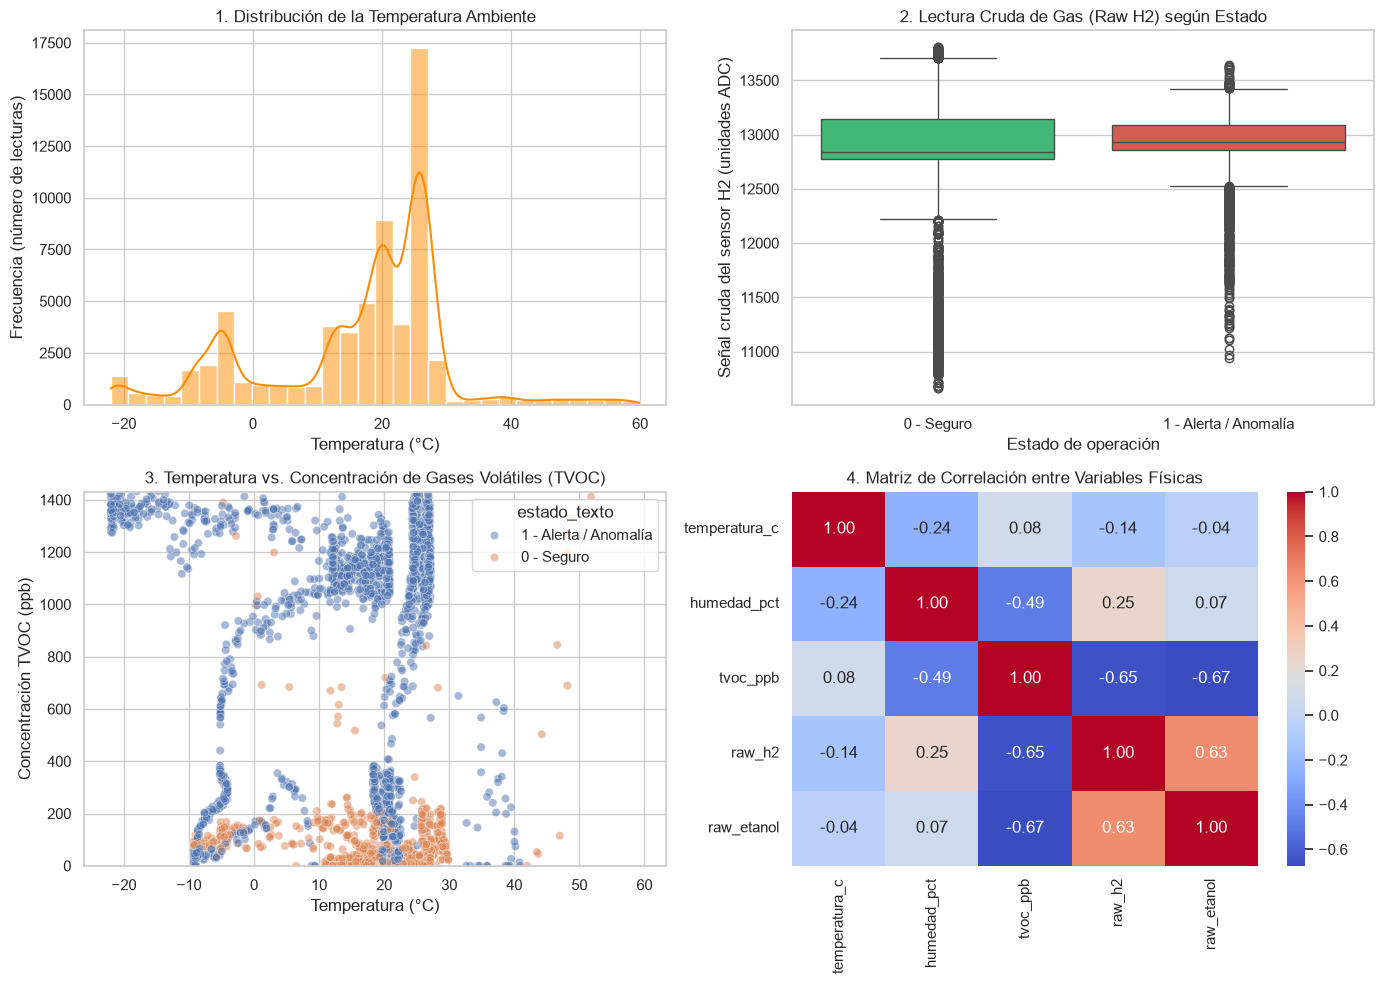

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Histograma de Temperatura (Distribución ambiental)
sns.histplot(data=df, x="temperatura_c", bins=30, kde=True, color="darkorange", ax=axes[0, 0])
axes[0, 0].set_title("1. Distribución de la Temperatura Ambiente")
axes[0, 0].set_xlabel("Temperatura (°C)")
axes[0, 0].set_ylabel("Frecuencia (número de lecturas)")

# Gráfico 2: Diagrama de Caja y Bigotes (Comparación de sensor de gas por estado)
sns.boxplot(data=df, x="estado_texto", y="raw_h2", palette=["#2ecc71", "#e74c3c"], ax=axes[0, 1])
axes[0, 1].set_title("2. Lectura Cruda de Gas (Raw H2) según Estado")
axes[0, 1].set_xlabel("Estado de operación")
axes[0, 1].set_ylabel("Señal cruda del sensor H2 (unidades ADC)")

# Gráfico 3: Dispersión (Relación entre Temperatura y Concentración TVOC)
muestra = df.sample(min(3000, len(df)), random_state=42) # Muestra aleatoria para visualizar sin saturar
sns.scatterplot(data=muestra, x="temperatura_c", y="tvoc_ppb", hue="estado_texto", alpha=0.5, ax=axes[1, 0])
axes[1, 0].set_title("3. Temperatura vs. Concentración de Gases Volátiles (TVOC)")
axes[1, 0].set_xlabel("Temperatura (°C)")
axes[1, 0].set_ylabel("Concentración TVOC (ppb)")
axes[1, 0].set_ylim(0, df["tvoc_ppb"].quantile(0.95)) # Recorte al percentil 95 para ver la tendencia clara

# Gráfico 4: Mapa de calor de correlación entre variables del sensor
corr = df[["temperatura_c", "humedad_pct", "tvoc_ppb", "raw_h2", "raw_etanol"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("4. Matriz de Correlación entre Variables Físicas")

plt.tight_layout()
plt.show()

### Interpretación y Conclusiones Preliminares
1. **Diferenciación por estado:** El diagrama de cajas muestra una separación clara en la mediana de las lecturas crudas del sensor (`Raw H2`) entre el estado seguro y el estado de alerta, aunque existen valores atípicos (*outliers*) en ambos grupos que explican por qué un umbral fijo genera falsas alarmas.
2. **Efecto térmico y ambiental:** La matriz de correlación evidencia que la temperatura y la humedad mantienen correlación con las lecturas de gas, confirmando la necesidad de un modelo multivariable (como propone **GasIA**) en lugar de reglas estáticas simples.
3. **Alcance:** Estas conclusiones son válidas para esta muestra pública de sensores IoT y sirven como línea base metodológica antes de entrenar con datos reales capturados en cocinas de Barrancabermeja.